# 04 · 仓库容量有限：线性规划

前面每种商品都是**单独**订货的。实际上门店仓库容量有限：50 种商品的订货量之和不能超过 `CAP` 件。如果按报童模型想订的量装不下，就要决定**削减哪些商品**。

两种做法：
1. **简单规则（启发式）：** 先分别计算各商品的订货量，装不下时所有商品**按相同比例**削减。
2. **线性规划：** 由求解器决定每种商品分配多少空间，使**期望损失最小**。

范围：2 号门店，50 种商品，2017 年 52 周，每周求解一次并计算实际损失。

求解器使用免费的 HiGHS（`pip install highspy`，已包含在 `requirements.txt` 中）。PuLP 4.x 不再自带求解器。

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pulp
from pathlib import Path

DATA = Path("../data")
FIG = Path("../figures")

print("PuLP", pulp.__version__, "| 可用求解器:", pulp.listSolvers(onlyAvailable=True))

PuLP 4.3.1 | 可用求解器: ['HiGHS']


## 1. 单个门店的数据

取 2 号门店和 notebook 02 中方法 C（LightGBM）的预测，整理成“周 × 商品”的预测表和实际销量表。

In [31]:
STORE = 2
fc = pd.read_csv(DATA / "forecasts.csv", parse_dates=["week"])
st = fc[fc["store"] == STORE]

def table(split, col):
    part = st[st["split"] == split]
    return part.pivot(index="week", columns="item", values=col).sort_index(axis=1)

pred_valid, sales_valid = table("valid", "pred_C"), table("valid", "sales")
pred_test, sales_test = table("test", "pred_C"), table("test", "sales")
ITEMS = list(pred_test.columns)
print("商品数:", len(ITEMS), "| 测试周数:", len(pred_test))

商品数: 50 | 测试周数: 52


## 2. 不同商品的利润不同

数据中没有价格。如果所有商品的缺货成本相同，按相同比例削减已经接近最优，线性规划几乎没有改进空间（本 notebook 最后会验证）。

因此**假设**各商品利润不同：缺货成本 `cu` 从 2 元（商品 1）线性增加到 10 元（商品 50），剩余成本 `co` 均为 3 元。每种商品的 CR 也不同：
- 商品 1：CR = 2 / (2 + 3) = 0.40，缺货代价小；
- 商品 50：CR = 10 / (10 + 3) = 0.77，需要多备货。

In [32]:
co = 3
cu = pd.Series(2 + 8 * (np.array(ITEMS) - 1) / 49, index=ITEMS)   # 从 2 到 10
CR = cu / (cu + co)
pd.DataFrame({"cu": cu, "CR": CR}).iloc[[0, 9, 24, 39, 49]].round(2)

,cu,CR
1,2.00,0.40
10,3.47,0.54
25,5.92,0.66
40,8.37,0.74
50,10.00,0.77


## 3. 需求情景（样本平均近似，SAA）

未来需求未知。不用正态分布假设，而是构造 **52 个可能的情景**：当周预测 + 2016 年每一周模型的实际预测误差。

例：预测 400，2016 年第 3 周误差为 +25 → 情景 3 = 425。

50 种商品的误差都取自**同一周**，从而保留商品之间的相关性：如果某周所有商品都卖得比预测好，这会出现在同一个情景里。

In [33]:
ERRORS = (sales_valid - pred_valid)[ITEMS].values      # 52 周 × 50 种商品
K = ERRORS.shape[0]

def scenarios(week):
    """K × 50 的矩阵：本周需求的可能取值。"""
    return np.maximum(0, pred_test.loc[week, ITEMS].values[None, :] + ERRORS)

D = scenarios(pred_test.index[0])
print("情景数:", D.shape[0], "| 商品数:", D.shape[1])
print("商品 1 的前 5 个情景:", D[:5, 0].round(1))

情景数: 52 | 商品数: 50
商品 1 的前 5 个情景: [174.1 168.1 119.5 161.7 144.1]


## 4. 仓库容量

假设仓库按 **2016 年平均周需求 + 10%** 设计。销量增长、夏季高峰时，2017 年有些周装不下理想的订货量。

In [34]:
CAP = 1.10 * sales_valid.sum(axis=1).mean()
weekly_demand_2017 = sales_test.sum(axis=1)
print(f"仓库容量: {CAP:,.0f} 件")
print(f"2017 年周需求: 平均 {weekly_demand_2017.mean():,.0f}, 最高 {weekly_demand_2017.max():,.0f}")

仓库容量: 28,014 件
2017 年周需求: 平均 26,410, 最高 33,981


## 5. 做法 1：各商品单独订货 + 按相同比例削减

不考虑容量时，每种商品的最优订货量是其情景在 CR 水平上的分位数（情景版的报童模型）。

如果总和超过 CAP，所有订货量乘以 `CAP / 总和`。例：想订 17,000，仓库 15,500 → 全部 × 0.91。

In [35]:
def order_separate(D):
    return np.array([np.quantile(D[:, i], CR.iloc[i]) for i in range(len(ITEMS))])

def order_proportional(D):
    q = order_separate(D)
    return q * min(1.0, CAP / q.sum())

## 6. 做法 2：线性规划

**决策变量：**
- `Q[i]`：商品 i 的订货量；
- `u[k, i]`：情景 k 中商品 i 的**缺货量**；
- `o[k, i]`：情景 k 中商品 i 的**剩余量**。

**目标：** 所有情景的平均损失最小：

`min (1/K) · Σ_k Σ_i ( cu[i] · u[k,i] + co · o[k,i] )`

**约束：**
- `u[k,i] ≥ D[k,i] − Q[i]`：缺货量不小于“需求 − 订货”；
- `o[k,i] ≥ Q[i] − D[k,i]`：剩余量不小于“订货 − 需求”；
- `Σ_i Q[i] ≤ CAP`：**仓库装得下**；
- `Q[i] ≥ 0.5 × 无容量限制时的订货量`：**最低陈列量**，每种商品至少保留一半。没有这条约束时，LP 在仓库紧张时会完全不订利润低的商品，这在数学上最优，但在商业上不现实。后面会比较有无这条约束的结果；
- 所有变量 ≥ 0。

**技巧：** 我们需要 `max(D − Q, 0)`，但 max 不是线性函数。引入 u 并加两个约束（u ≥ D − Q，u ≥ 0）。u 在目标函数中有成本，求解器会把它压到最小，最优时 u 恰好等于 max(D − Q, 0)，问题因此保持**线性**。

规模：50 + 2 × 52 × 50 = **5,250 个变量**，HiGHS 不到 1 秒即可求解。

**关于 PuLP 4：** 网上很多例子使用旧写法 `pulp.LpVariable(...)`；PuLP 4 中通过问题对象创建变量：`prob.add_variable_dict(...)`。

In [36]:
def order_lp(D, capacity=CAP, min_share=0.5):
    K, I = D.shape
    q_free = order_separate(D)      # 不考虑容量时的订货量
    prob = pulp.LpProblem("store_orders", pulp.LpMinimize)
    Q = prob.add_variable_dict("Q", range(I), lowBound=0)
    u = prob.add_variable_dict("u", (range(K), range(I)), lowBound=0)
    o = prob.add_variable_dict("o", (range(K), range(I)), lowBound=0)

    # 目标：各情景的平均损失
    prob += pulp.lpSum(cu.iloc[i] * u[k, i] + co * o[k, i]
                       for k in range(K) for i in range(I)) / K

    # 每个情景中的缺货量和剩余量
    for k in range(K):
        for i in range(I):
            prob += u[k, i] >= D[k, i] - Q[i]
            prob += o[k, i] >= Q[i] - D[k, i]

    # 仓库容量
    prob += pulp.lpSum(Q[i] for i in range(I)) <= capacity, "capacity"

    # 最低陈列量
    for i in range(I):
        prob += Q[i] >= min_share * q_free[i]

    prob.solve(pulp.HiGHS(msg=False))
    q = np.array([Q[i].value() for i in range(I)])
    shadow = -prob.get_constraint_by_name("capacity").pi   # 影子价格（见下文）
    return q, shadow

**验证 LP 的写法：** 如果仓库无限大，容量约束不起作用，LP 的结果应与“各商品单独订货”（CR 分位数）一致。

In [37]:
D = scenarios(pred_test.index[0])
q_lp_big, _ = order_lp(D, capacity=1e9)
q_sep = order_separate(D)
print("无容量限制的 LP 与分位数的最大差异:", np.abs(q_lp_big - q_sep).max().round(2), "件")

无容量限制的 LP 与分位数的最大差异: 2.06 件


差异不为零但很小：两个相邻情景之间的任何订货量平均损失都相同，最优解不唯一。NumPy 取中间值，求解器取端点，二者都是最优的。

## 7. 2017 年：每周求解

52 周 × 2 个线性规划（有、无最低陈列量），约 30–60 秒。

In [38]:
def loss(q, actual):
    q = np.round(q)
    return (cu.values * np.maximum(actual - q, 0) + co * np.maximum(q - actual, 0)).sum()

rows = []
for week in pred_test.index:
    D = scenarios(week)
    actual = sales_test.loc[week, ITEMS].values
    q_sep = order_separate(D)
    q_prop = order_proportional(D)
    q_lp, shadow = order_lp(D)
    q_lp0, _ = order_lp(D, min_share=0.0)
    rows.append({
        "week": week,
        "wanted": q_sep.sum(),
        "binding": q_sep.sum() > CAP,
        "loss_no_limit": loss(q_sep, actual),
        "loss_proportional": loss(q_prop, actual),
        "loss_lp": loss(q_lp, actual),
        "loss_lp_no_min": loss(q_lp0, actual),
        "shadow_price": shadow,
    })

res = pd.DataFrame(rows)
print("仓库装不下理想订货量的周数:", res["binding"].sum(), "/", len(res))

仓库装不下理想订货量的周数: 30 / 52


In [39]:
summary = pd.Series({
    "不考虑容量（参照）": res["loss_no_limit"].sum(),
    "按相同比例削减": res["loss_proportional"].sum(),
    "LP（含最低陈列量）": res["loss_lp"].sum(),
    "LP（不含最低陈列量）": res["loss_lp_no_min"].sum(),
}) / 1000
saving = 100 * (1 - summary["LP（含最低陈列量）"] / summary["按相同比例削减"])
print(summary.round(1).to_string(), "\n（2017 年，千元）")
print(f"\n含最低陈列量的 LP 比简单规则节省 {saving:.1f}%")

不考虑容量（参照）      309.4
按相同比例削减        532.2
LP（含最低陈列量）     468.1
LP（不含最低陈列量）    449.7 
（2017 年，千元）

含最低陈列量的 LP 比简单规则节省 12.0%


## 8. LP 是怎样分配空间的

取仓库最紧张的一周，比较两种做法对每种商品的削减比例（相对于无容量限制的订货量）。

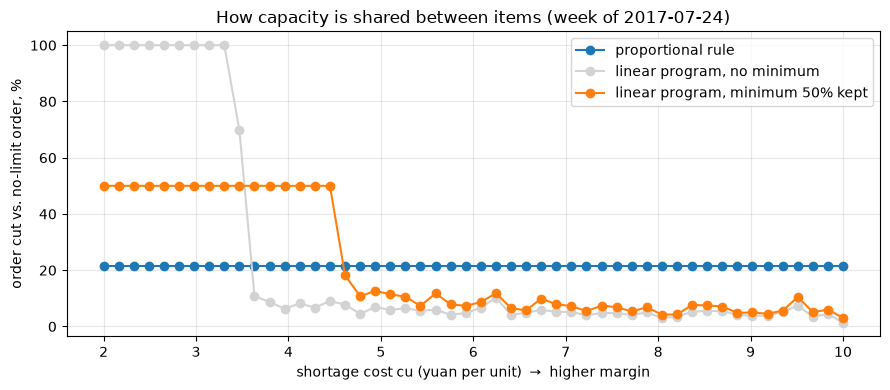

In [40]:
tight_week = res.loc[(res["wanted"] - CAP).idxmax(), "week"]
D = scenarios(tight_week)
q_sep = order_separate(D)
q_prop = order_proportional(D)
q_lp, _ = order_lp(D)
q_lp0, _ = order_lp(D, min_share=0.0)

cut_lp0 = 100 * (1 - q_lp0 / q_sep)
cut_prop = 100 * (1 - q_prop / q_sep)
cut_lp = 100 * (1 - q_lp / q_sep)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(cu.values, cut_prop, "o-", label="proportional rule")
ax.plot(cu.values, cut_lp0, "o-", color="lightgray", label="linear program, no minimum")
ax.plot(cu.values, cut_lp, "o-", label="linear program, minimum 50% kept")
ax.set_xlabel("shortage cost cu (yuan per unit)  →  higher margin")
ax.set_ylabel("order cut vs. no-limit order, %")
ax.set_title(f"How capacity is shared between items (week of {tight_week.date()})")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "04_cut_by_margin.png", dpi=150)
plt.show()

**解读：**
- 简单规则对所有商品削减相同比例（水平线）；
- LP 优先削减**利润低**的商品（削减到最低陈列量），几乎不动**利润高**的商品：仓库空间给了每件带来收益最多的商品；
- **灰线**是不含最低陈列量的 LP：利润低的商品被削减 100%，即完全不订。线性规划的最优解常常位于可行域的“顶点”，会把决策推到极端，因此业务约束必须明确写进模型。

## 9. 影子价格

求解后，求解器给出容量约束的**影子价格**（对偶变量）：**仓库每多 1 个位置，期望损失能减少多少元**。

- 仓库不满 → 影子价格为 0，多余的位置没有价值；
- 仓库装不下 → 影子价格 > 0。例如 3.5 表示“多 1 个位置，本周可减少 3.5 元损失”。

这直接回答了管理问题：**是否值得扩大仓库、愿意为此付多少钱**。如果租一个位置的成本低于影子价格，扩容就是划算的。

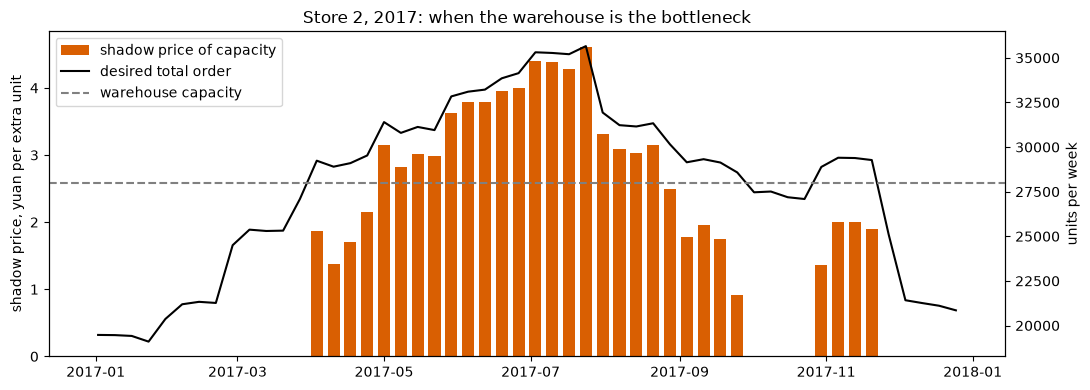

仓库紧张周的平均影子价格: 2.82 元/位


In [41]:
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(res["week"], res["shadow_price"], width=5, color="#d95f02", label="shadow price of capacity")
ax1.set_ylabel("shadow price, yuan per extra unit")
ax2 = ax1.twinx()
ax2.plot(res["week"], res["wanted"], color="black", lw=1.5, label="desired total order")
ax2.axhline(CAP, color="gray", ls="--", label="warehouse capacity")
ax2.set_ylabel("units per week")
ax1.set_title(f"Store {STORE}, 2017: when the warehouse is the bottleneck")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc="upper left")
plt.tight_layout()
plt.savefig(FIG / "04_shadow_price.png", dpi=150)
plt.show()

print("仓库紧张周的平均影子价格:",
      round(res.loc[res["binding"], "shadow_price"].mean(), 2), "元/位")

## 10. 对照实验：如果所有商品利润相同

令所有商品 cu = 6，重复比较。预期 LP 与简单规则的差距会很小。

In [42]:
cu_saved = cu.copy()
cu = pd.Series(6.0, index=ITEMS)
CR = cu / (cu + co)

equal = {"prop": 0.0, "lp": 0.0}
for week in pred_test.index:
    D = scenarios(week)
    actual = sales_test.loc[week, ITEMS].values
    equal["prop"] += loss(order_proportional(D), actual)
    equal["lp"] += loss(order_lp(D)[0], actual)

print(f"利润相同：简单规则 {equal['prop']/1000:.1f}，LP {equal['lp']/1000:.1f} 千元")
print(f"LP 节省: {100 * (1 - equal['lp'] / equal['prop']):.1f}%")

cu = cu_saved            # 恢复不同利润的设定
CR = cu / (cu + co)

利润相同：简单规则 559.2，LP 563.2 千元
LP 节省: -0.7%


## 11. 保存

In [43]:
res.to_csv(DATA / "capacity_lp_results.csv", index=False)
summary.rename("loss_thousand_yuan").to_csv(DATA / "capacity_lp_summary.csv")
print("已保存")

已保存


## 小结

- 2017 年有 30 周仓库装不下理想订货量。含最低陈列量的 LP 损失比按相同比例削减少约 12%，挽回了容量不足所造成额外损失的约 29%。
- LP 优先削减利润低的商品；不加最低陈列量会完全放弃这些商品，保留最低陈列量的代价约 1.8 万元。
- 影子价格在仓库不紧时为 0，7 月最高约 4.6 元/位/周，可用于判断何时扩容划算。
- 所有商品利润相同时，LP 并不优于简单规则：LP 的优势来自商品之间的差异。